Import Library

In [1]:
# 1. IMPORT LIBRARY
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

# Library Machine Learning (Scikit-Learn & XGBoost)
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')
print("Semua library berhasil dimuat!")

Semua library berhasil dimuat!


Data Acquisition & Preprocessing (One-Hot Encoding)

In [2]:
# 2. DATA ACQUISITION
# Membaca dataset mutasi (Pastikan nama file sesuai dengan yang Anda upload)
df = pd.read_csv('dataset_mutasi_pns.csv')

# 3. DATA PREPROCESSING
# A. Menghapus (Drop) kolom identitas yang tidak relevan untuk pemodelan ML
kolom_identitas = ['Nama', 'Usia', 'Pendidikan', 'Riwayat_Jabatan']
df_bersih = df.drop(columns=kolom_identitas)

# B. Label Encoding untuk Kolom Target (Layak = 1, Tidak Layak = 0)
df_bersih['Kelayakan_Mutasi'] = df_bersih['Kelayakan_Mutasi'].map({'Layak': 1, 'Tidak Layak': 0})

# Pemisahan Fitur (X) dan Target (y)
X = df_bersih.drop(columns=['Kelayakan_Mutasi'])
y = df_bersih['Kelayakan_Mutasi']

# C. One-Hot Encoding (Mengubah data teks kategori menjadi angka numerik)
X_encoded = pd.get_dummies(X, drop_first=True)

print("Shape Fitur X setelah One-Hot Encoding:", X_encoded.shape)
X_encoded.head()

Shape Fitur X setelah One-Hot Encoding: (200, 10)


,Masa_Kerja,Hasil_Kerja_Di Bawah Ekspektasi,Hasil_Kerja_Sesuai Ekspektasi,Perilaku_Kerja_Di Bawah Ekspektasi,Perilaku_Kerja_Sesuai Ekspektasi,Kelengkapan_Berkas_Tidak Lengkap,Sedang_Hukuman_Disiplin_Ya,Bebas_Temuan_Inspektorat_Ya,Sedang_Tugas_Belajar_Ya,Kesesuaian_Formasi_ABK_Tidak Sesuai
0,19,False,True,False,True,False,False,True,False,False
1,0,True,False,False,False,True,False,True,False,False
2,14,False,True,False,False,False,False,True,False,False
3,0,False,True,False,True,False,False,True,False,False
4,0,False,False,False,True,False,False,True,False,False


Data Splitting & Handling Imbalance Data (SMOTE)

In [3]:
# 4. DATA SPLITTING
# Membagi data menjadi Data Latih (80%) dan Data Uji (20%)
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42, stratify=y)

print(f"Jumlah data latih sebelum SMOTE: {len(y_train)} (Layak: {sum(y_train==1)}, Tidak Layak: {sum(y_train==0)})")

# 5. HANDLING IMBALANCE DATA DENGAN SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(f"Jumlah data latih setelah SMOTE: {len(y_train_smote)} (Layak: {sum(y_train_smote==1)}, Tidak Layak: {sum(y_train_smote==0)})")

Jumlah data latih sebelum SMOTE: 160 (Layak: 70, Tidak Layak: 90)
Jumlah data latih setelah SMOTE: 180 (Layak: 90, Tidak Layak: 90)


Hyperparameter Tuning & Model Building XGBoost

In [12]:
# 6. HYPERPARAMETER TUNING & MODEL BUILDING XGBOOST
# Inisialisasi model dasar
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss')

# Menentukan ruang pencarian hyperparameter (sesuai literatur skripsi)
param_grid = {
    'learning_rate': [0.01, 0.03, 0.05],
    'max_depth': [2, 3, 4],
    'n_estimators': [50, 60, 80]
}

# Konfigurasi Stratified K-Fold (k=5)
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Menjalankan Grid Search
print("Memulai Hyperparameter Tuning... (Tunggu sebentar)")
grid_search = GridSearchCV(estimator=xgb_model, param_grid=param_grid,
                           cv=cv_strategy, scoring='accuracy', n_jobs=-1, verbose=0)

grid_search.fit(X_train_smote, y_train_smote)

# Mengambil model terbaik
best_xgb_model = grid_search.best_estimator_

print("\nModel Building Selesai!")
print("Kombinasi Hyperparameter Terbaik:", grid_search.best_params_)

Memulai Hyperparameter Tuning... (Tunggu sebentar)

Model Building Selesai!
Kombinasi Hyperparameter Terbaik: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 60}


Model Evaluation & Diagnosa (Overfitting/Underfitting)

In [13]:
# 7. MODEL EVALUATION & DIAGNOSA
# Melatih ulang dengan eval_set untuk merekam grafik Learning Curve nanti
eval_set = [(X_train_smote, y_train_smote), (X_test, y_test)]
best_xgb_model.fit(X_train_smote, y_train_smote, eval_set=eval_set, verbose=False)

# Melakukan prediksi pada data latih dan data uji
y_pred_train = best_xgb_model.predict(X_train_smote)
y_pred_test = best_xgb_model.predict(X_test)

# Menghitung Metrik Kinerja
acc_train = accuracy_score(y_train_smote, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)
prec = precision_score(y_test, y_pred_test)
rec = recall_score(y_test, y_pred_test)
f1 = f1_score(y_test, y_pred_test)

print("=== HASIL EVALUASI MODEL XGBOOST ===")
print(f"Akurasi Data Latih : {acc_train * 100:.2f}%")
print(f"Akurasi Data Uji   : {acc_test * 100:.2f}%")
print(f"Presisi (Precision): {prec * 100:.2f}%")
print(f"Recall             : {rec * 100:.2f}%")
print(f"F1-Score           : {f1 * 100:.2f}%\n")

# Logika Deteksi Overfitting / Underfitting
print("=== DIAGNOSA KONDISI MODEL ===")
if acc_train < 0.70 and acc_test < 0.70:
    print("=> Status: UNDERFITTING (Model gagal mempelajari pola data, akurasi terlalu rendah)")
elif (acc_train - acc_test) > 0.10:
    print("=> Status: OVERFITTING (Model terlalu menghafal data training, tapi gagal di data baru)")
else:
    print("=> Status: OPTIMAL / BEST FIT (Model sangat baik, stabil, dan Robust!)")

=== HASIL EVALUASI MODEL XGBOOST ===
Akurasi Data Latih : 98.33%
Akurasi Data Uji   : 95.00%
Presisi (Precision): 89.47%
Recall             : 100.00%
F1-Score           : 94.44%

=== DIAGNOSA KONDISI MODEL ===
=> Status: OPTIMAL / BEST FIT (Model sangat baik, stabil, dan Robust!)


Visualisasi Hasil

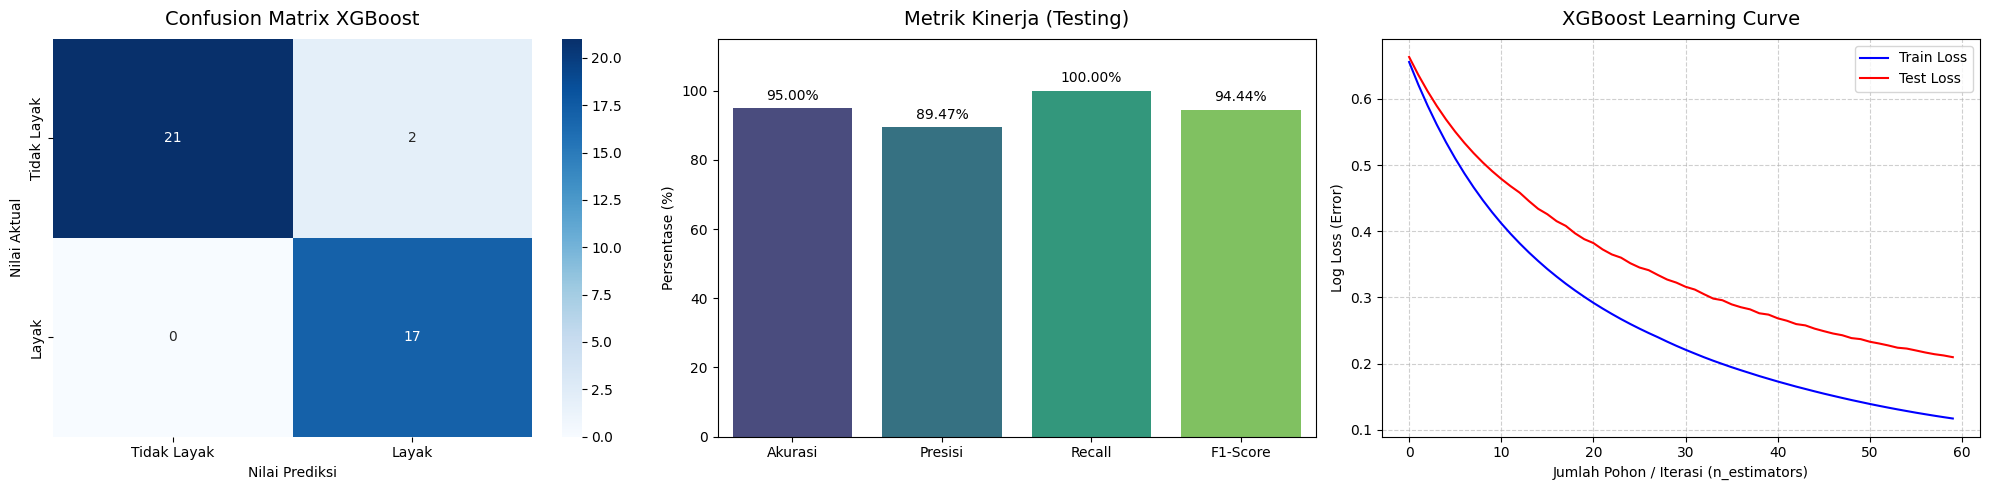

In [14]:
# 8. VISUALISASI HASIL
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# A. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Tidak Layak', 'Layak'],
            yticklabels=['Tidak Layak', 'Layak'], ax=axes[0])
axes[0].set_title('Confusion Matrix XGBoost', fontsize=14, pad=10)
axes[0].set_ylabel('Nilai Aktual')
axes[0].set_xlabel('Nilai Prediksi')

# B. Bar Chart Metrik Kinerja
metrics_names = ['Akurasi', 'Presisi', 'Recall', 'F1-Score']
metrics_values = [acc_test*100, prec*100, rec*100, f1*100]
sns.barplot(x=metrics_names, y=metrics_values, palette='viridis', ax=axes[1])
axes[1].set_ylim(0, 115)
axes[1].set_title('Metrik Kinerja (Testing)', fontsize=14, pad=10)
axes[1].set_ylabel('Persentase (%)')
for p in axes[1].patches:
    axes[1].annotate(format(p.get_height(), '.2f') + '%',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha = 'center', va = 'center', xytext = (0, 9), textcoords = 'offset points')

# C. Learning Curve (Log Loss)
results = best_xgb_model.evals_result()
epochs = len(results['validation_0']['logloss'])
x_axis = range(0, epochs)
axes[2].plot(x_axis, results['validation_0']['logloss'], label='Train Loss', color='blue')
axes[2].plot(x_axis, results['validation_1']['logloss'], label='Test Loss', color='red')
axes[2].legend()
axes[2].set_ylabel('Log Loss (Error)')
axes[2].set_xlabel('Jumlah Pohon / Iterasi (n_estimators)')
axes[2].set_title('XGBoost Learning Curve', fontsize=14, pad=10)
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Export Model

In [15]:
# 9. MODEL EXPORT / IMPLEMENTATION PREP
# Menyimpan model ke dalam format .pkl menggunakan pickle
filename = 'model_xgboost_mutasi.pkl'
pickle.dump(best_xgb_model, open(filename, 'wb'))

# Menyimpan urutan kolom (fitur) agar input dari Web/Laravel urutannya tidak terbalik
kolom_fitur = X_encoded.columns.tolist()
pickle.dump(kolom_fitur, open('kolom_fitur_mutasi.pkl', 'wb'))

print(f"Model berhasil diexport dengan nama: {filename}")
print("Silakan download file .pkl tersebut dari panel Files (folder) di sebelah kiri.")

Model berhasil diexport dengan nama: model_xgboost_mutasi.pkl
Silakan download file .pkl tersebut dari panel Files (folder) di sebelah kiri.


In [17]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
